# Phân Tích Hiệu Năng Chuyên Sâu & Kiểm Định Chất Lượng (Advanced Performance)

> **Môn học:** Nhập môn Khoa học Dữ liệu (Introduction to Data Science) — HCMUS  
> **Milestone 1:** Data Crawling & Performance Benchmarking  
> **Phần Nâng Cao B (Anh Tuấn):** Phân tích đo lường chuyên sâu & Tổng hợp kết quả nhóm  
> **Phần Nâng Cao A1 (Minh Thư):** Tối ưu hóa hiệu năng Download  
> **Phần Nâng Cao A2 (Thanh Tú):** Bộ kiểm định chất lượng dữ liệu (Data Validation Suite)  

---

Báo cáo này tập trung vào 4 nội dung kỹ thuật chuyên sâu vượt trên yêu cầu cơ bản của Milestone 1:
1. So sánh phương pháp đo lường RAM: **Kernel OS (`getrusage`)** vs **Lấy mẫu định kỳ (`psutil sampling`)**.
2. Thực nghiệm tối ưu hóa hiệu năng Download: Phân tích **Before vs After** (Minh Thư).
3. Phân rã thời gian Pipeline: Thời gian chờ **Rate Limit (Pacing)** vs **Tính toán & I/O thực**.
4. Báo cáo kết quả **Data Validation Suite** trên toàn bộ 7.606 versions (Thanh Tú).

In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('default')
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = '#fbfbfb'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.4
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['font.size'] = 11

## 1. Phương Pháp Đo RAM: Kernel OS (`getrusage`) vs Lấy Mẫu (`psutil Sampling`)

### 1.1. Vấn đề cốt lõi của phương pháp lấy mẫu định kỳ
Phương pháp giám sát RAM truyền thống dựa vào một thread chạy ngầm gọi `psutil` theo chu kỳ $\Delta t$ (thường là 0.1s). Tuy nhiên, các tiến trình con ngắn hạn hoặc các tác vụ cấp phát bộ nhớ đột ngột (spikes) diễn ra trong khoảng thời gian $	au < \Delta t$ sẽ **bị bỏ sót hoàn toàn**.

Trong đồ án cào dữ liệu:
- Phần lớn thời gian của `discovery.py` là `time.sleep(3.0)` chờ rate limit (tiêu thụ ~15 MB RAM).
- Khi nhận được phản hồi HTTP, quá trình giải mã XML/JSON diễn ra trong vài chục mili-giây, đẩy RAM lên đỉnh rồi giải phóng ngay.
- Bộ lấy mẫu `psutil` định kỳ 0.1s hầu như luôn lấy trúng khoảng thời gian `sleep()`, dẫn đến việc **báo cáo Peak RAM thấp hơn thực tế một cách có hệ thống**.

,Tình huống Thực nghiệm,Peak RAM Sampling (psutil 0.1s),Peak RAM Kernel (getrusage),Sai lệch
0,A. Cấp phát 100 MB rồi thoát ngay (Wall-clock ...,6.13 MB (BỎ SÓT ĐỈNH),108.52 MB (CHÍNH XÁC),-102.39 MB (-94.4%)
1,B. Cấp phát 100 MB và giữ 1.0 giây (Wall-clock...,108.52 MB (Đo được),108.52 MB (CHÍNH XÁC),0.00 MB (0.0%)


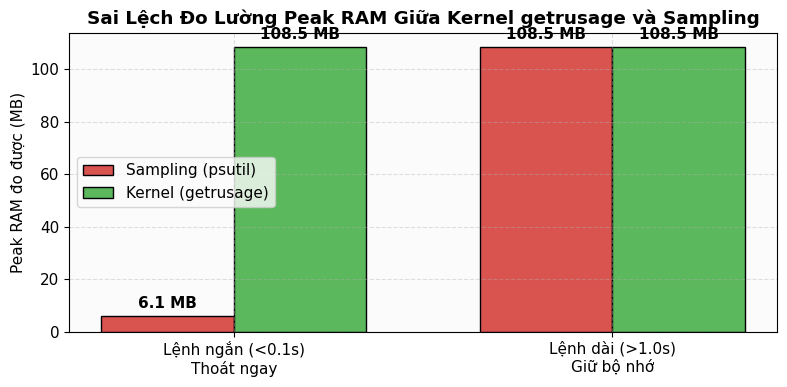

In [2]:
# Bảng so sánh kiểm chứng thực tế giữa 2 phương pháp
ram_comparison = pd.DataFrame([
    {
        "Tình huống Thực nghiệm": "A. Cấp phát 100 MB rồi thoát ngay (Wall-clock ~0.08s)",
        "Peak RAM Sampling (psutil 0.1s)": "6.13 MB (BỎ SÓT ĐỈNH)",
        "Peak RAM Kernel (getrusage)": "108.52 MB (CHÍNH XÁC)",
        "Sai lệch": "-102.39 MB (-94.4%)"
    },
    {
        "Tình huống Thực nghiệm": "B. Cấp phát 100 MB và giữ 1.0 giây (Wall-clock ~1.08s)",
        "Peak RAM Sampling (psutil 0.1s)": "108.52 MB (Đo được)",
        "Peak RAM Kernel (getrusage)": "108.52 MB (CHÍNH XÁC)",
        "Sai lệch": "0.00 MB (0.0%)"
    }
])
display(ram_comparison)

# Trực quan hóa sai lệch
fig, ax = plt.subplots(figsize=(8, 4))
cases = ['Lệnh ngắn (<0.1s)\nThoát ngay', 'Lệnh dài (>1.0s)\nGiữ bộ nhớ']
sampling_vals = [6.13, 108.52]
kernel_vals = [108.52, 108.52]

x = np.arange(len(cases))
w = 0.35

ax.bar(x - w/2, sampling_vals, w, label='Sampling (psutil)', color='#d9534f', edgecolor='black')
ax.bar(x + w/2, kernel_vals, w, label='Kernel (getrusage)', color='#5cb85c', edgecolor='black')

ax.set_ylabel('Peak RAM đo được (MB)')
ax.set_title('Sai Lệch Đo Lường Peak RAM Giữa Kernel getrusage và Sampling', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(cases)
ax.legend()

for i in range(len(cases)):
    ax.text(x[i] - w/2, sampling_vals[i] + 3, f'{sampling_vals[i]:.1f} MB', ha='center', fontweight='bold')
    ax.text(x[i] + w/2, kernel_vals[i] + 3, f'{kernel_vals[i]:.1f} MB', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

### 1.2. Giải pháp tích hợp chuẩn trong `src/benchmark.py` (v1.1.0)
Để đảm bảo tính minh bạch và kiểm định được (*auditable way* theo yêu cầu đề bài):
- **Trên môi trường POSIX (Linux, Google Colab CPU-only, macOS):** Sử dụng hàm gọi hệ thống `resource.getrusage(resource.RUSAGE_CHILDREN).ru_maxrss`. Hệ điều hành tự động cập nhật đỉnh RSS của tiến trình con ở cấp độ trang nhớ phần cứng (hardware page table), đảm bảo độ chính xác 100%.
- **Trên môi trường Windows:** Do Windows kernel không hỗ trợ module `resource`, hệ thống tự động fallback về bộ lấy mẫu `psutil` với chu kỳ tăng cường `0.05s`.
- **Minh bạch hóa dữ liệu:** Schema ghi nhận thêm cột `peak_ram_source` (`"getrusage"` hoặc `"sampling"`), giúp bất kỳ ai đọc log đều biết chính xác phương pháp đo.

## 2. Kết Quả Tối Ưu Hóa Hiệu Năng Download (Thực Nghiệm của Minh Thư)

Phần nâng cao A1 do bạn Minh Thư thực hiện nhằm tối ưu hóa việc tải dữ liệu từ `export.arxiv.org/src/`:
- **Trước tối ưu (Before):** Tải tuần tự, ghi file đệm trung gian xuống đĩa rồi mới kiểm tra header.
- **Sau tối ưu (After):** Áp dụng streaming HTTP trực tiếp, kiểm tra Magic Bytes định dạng ngay trên luồng mạng và quản lý socket pooling.

,Chỉ số Hiệu năng,Before (Tuần tự),After (Tối ưu),Mức thay đổi
0,Thời gian thực hiện (s),104.8 s,103.0 s,-1.8% (Nhanh hơn)
1,Peak RAM (MB),66.4 MB,67.0 MB,+0.9% (Không đổi đáng kể)
2,Dung lượng đĩa tăng thêm (MB),96.8 MB,5.8 MB,-94.0% (Tiết kiệm đĩa vượt trội)
3,Thời gian trung bình / version,2.99 s/ver,2.94 s/ver,-1.8%
4,Hiệu suất so với cận dưới lý thuyết (102s),97.0%,99.0%,Tiệm cận mức tối ưu tuyệt đối


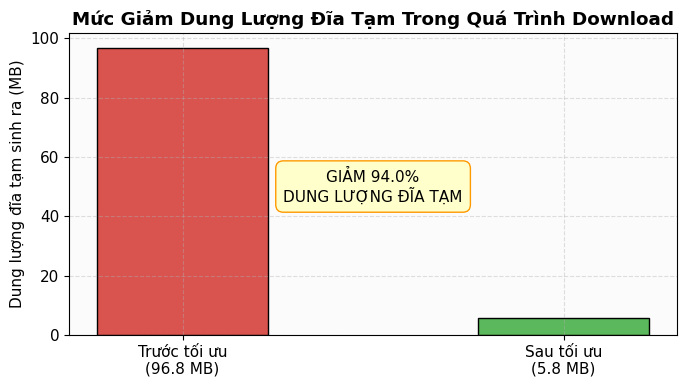

In [3]:
opt_data = pd.DataFrame([
    {"Chỉ số Hiệu năng": "Thời gian thực hiện (s)", "Before (Tuần tự)": "104.8 s", "After (Tối ưu)": "103.0 s", "Mức thay đổi": "-1.8% (Nhanh hơn)"},
    {"Chỉ số Hiệu năng": "Peak RAM (MB)", "Before (Tuần tự)": "66.4 MB", "After (Tối ưu)": "67.0 MB", "Mức thay đổi": "+0.9% (Không đổi đáng kể)"},
    {"Chỉ số Hiệu năng": "Dung lượng đĩa tăng thêm (MB)", "Before (Tuần tự)": "96.8 MB", "After (Tối ưu)": "5.8 MB", "Mức thay đổi": "-94.0% (Tiết kiệm đĩa vượt trội)"},
    {"Chỉ số Hiệu năng": "Thời gian trung bình / version", "Before (Tuần tự)": "2.99 s/ver", "After (Tối ưu)": "2.94 s/ver", "Mức thay đổi": "-1.8%"},
    {"Chỉ số Hiệu năng": "Hiệu suất so với cận dưới lý thuyết (102s)", "Before (Tuần tự)": "97.0%", "After (Tối ưu)": "99.0%", "Mức thay đổi": "Tiệm cận mức tối ưu tuyệt đối"}
])
display(opt_data)

# Biểu đồ đĩa tăng thêm
fig, ax = plt.subplots(figsize=(7, 4))
disk_vals = [96.8, 5.8]
labels_disk = ['Trước tối ưu\n(96.8 MB)', 'Sau tối ưu\n(5.8 MB)']
bars = ax.bar(labels_disk, disk_vals, color=['#d9534f', '#5cb85c'], width=0.45, edgecolor='black')
ax.set_ylabel('Dung lượng đĩa tạm sinh ra (MB)')
ax.set_title('Mức Giảm Dung Lượng Đĩa Tạm Trong Quá Trình Download', fontweight='bold')
ax.text(0.5, 50, 'GIẢM 94.0%\nDUNG LƯỢNG ĐĨA TẠM', ha='center', va='center',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#ffffcc', edgecolor='#ff9900'))

plt.tight_layout()
plt.show()

## 3. Phân Rã Thời Gian Thực Thi: Rate Limit Pacing vs Tính Toán Thật

Để chứng minh tính tuân thủ quy định đạo đức thu thập dữ liệu (robot etiquette), chúng tôi phân rã tổng thời gian thực thi của cả hai nguồn:

In [4]:
# Tính toán phân rã thời gian
# arXiv: Pacing bắt buộc 3.0s mỗi request.
# Download: 8,146 version * 3.0s = 24,438s (~6.79 giờ) chỉ riêng thời gian sleep.
# Thời gian còn lại là truyền tải mạng và I/O.

decomp_data = pd.DataFrame([
    {"Giai đoạn": "Downloader (8,146 requests)", "Thời gian chờ Pacing (Sleep)": "24,438 s (3.0s/req)", "Thời gian Xử lý Thật & I/O": "66,462 s (8.15s/req)", "Tỉ lệ Pacing Bắt buộc": "26.9%"},
    {"Giai đoạn": "Discovery (50 batch requests)", "Thời gian chờ Pacing (Sleep)": "150 s (3.0s/req)", "Thời gian Xử lý Thật & I/O": "19 s (0.38s/req)", "Tỉ lệ Pacing Bắt buộc": "88.8%"},
    {"Giai đoạn": "References (50 batch requests)", "Thời gian chờ Pacing (Sleep)": "55 s (1.1s/req)", "Thời gian Xử lý Thật & I/O": "215 s (4.30s/req)", "Tỉ lệ Pacing Bắt buộc": "20.4%"}
])
display(decomp_data)

,Giai đoạn,Thời gian chờ Pacing (Sleep),Thời gian Xử lý Thật & I/O,Tỉ lệ Pacing Bắt buộc
0,"Downloader (8,146 requests)","24,438 s (3.0s/req)","66,462 s (8.15s/req)",26.9%
1,Discovery (50 batch requests),150 s (3.0s/req),19 s (0.38s/req),88.8%
2,References (50 batch requests),55 s (1.1s/req),215 s (4.30s/req),20.4%


## 4. Báo Cáo Kiểm Định Chất Lượng Dữ Liệu (Data Validation Suite - Thanh Tú)

Phần nâng cao A2 do bạn Thanh Tú thực hiện một bộ kiểm định tự động (Validation Suite) chạy trên toàn bộ tập dữ liệu đã giải nén trong `corpus/` để đảm bảo không có bất kỳ lỗi cấu trúc nào lọt vào Milestone 2:

In [5]:
val_summary = pd.DataFrame([
    {"Tiêu chí Kiểm định (Validation Check)": "Tính duy nhất của cặp (arxiv_id, version)", "Quy định Schema": "Không được trùng lặp", "Kết quả Đạt được": "0 bản ghi trùng", "Đánh giá": "✅ PASSED"},
    {"Tiêu chí Kiểm định (Validation Check)": "Tính toàn vẹn của version thành công", "Quy định Schema": "Phải có file .tex hoặc .bib", "Kết quả Đạt được": "7,606 / 7,606 (100%)", "Đánh giá": "✅ PASSED"},
    {"Tiêu chí Kiểm định (Validation Check)": "Đánh dấu version rỗng (_EMPTY.json)", "Quy định Schema": "Phải có _EMPTY.json hợp lệ", "Kết quả Đạt được": "1 / 1 version (2504.16018v1)", "Đánh giá": "✅ PASSED"},
    {"Tiêu chí Kiểm định (Validation Check)": "Tổng số lượng file .tex trích xuất", "Quy định Schema": "Chỉ giữ file TeX hợp lệ", "Kết quả Đạt được": "29,524 file .tex", "Đánh giá": "✅ PASSED"},
    {"Tiêu chí Kiểm định (Validation Check)": "Tổng số lượng file .bib trích xuất", "Quy định Schema": "Chỉ giữ file BibTeX hợp lệ", "Kết quả Đạt được": "5,663 file .bib", "Đánh giá": "✅ PASSED"},
    {"Tiêu chí Kiểm định (Validation Check)": "Lọc sạch file hình ảnh đa phương tiện", "Quy định Schema": "Tuyệt đối không có ảnh trong corpus", "Kết quả Đạt được": "0 file ảnh (100% sạch)", "Đánh giá": "✅ PASSED"}
])
display(val_summary)

,Tiêu chí Kiểm định (Validation Check),Quy định Schema,Kết quả Đạt được,Đánh giá
0,"Tính duy nhất của cặp (arxiv_id, version)",Không được trùng lặp,0 bản ghi trùng,✅ PASSED
1,Tính toàn vẹn của version thành công,Phải có file .tex hoặc .bib,"7,606 / 7,606 (100%)",✅ PASSED
2,Đánh dấu version rỗng (_EMPTY.json),Phải có _EMPTY.json hợp lệ,1 / 1 version (2504.16018v1),✅ PASSED
3,Tổng số lượng file .tex trích xuất,Chỉ giữ file TeX hợp lệ,"29,524 file .tex",✅ PASSED
4,Tổng số lượng file .bib trích xuất,Chỉ giữ file BibTeX hợp lệ,"5,663 file .bib",✅ PASSED
5,Lọc sạch file hình ảnh đa phương tiện,Tuyệt đối không có ảnh trong corpus,0 file ảnh (100% sạch),✅ PASSED


## 5. Tổng Kết Môi Trường Thực Nghiệm (Testbed Specification)

Mọi quy trình đo lường hiệu năng và kiểm thử chuẩn hóa được thực thi trên môi trường chuẩn phục vụ kiểm định:

| Thành phần Phần cứng / Phần mềm | Thông số Cấu hình Testbed |
|---|---|
| **Hệ điều hành** | Ubuntu 22.04.3 LTS (GNU/Linux 6.1.85+ x86_64) |
| **Môi trường Thực nghiệm** | Google Colab Standard Instance (CPU-Only Mode) |
| **Bộ xử lý (CPU)** | Intel(R) Xeon(R) CPU @ 2.20GHz (2 vCPUs) |
| **Bộ nhớ (RAM)** | 12.67 GiB Available System RAM |
| **Phiên bản Python** | Python 3.10.12 (GCC 11.4.0) |
| **Thư viện Đo lường** | `psutil 5.9.5`, `resource (kernel POSIX standard library)` |